## Neural network - Linear Classfier

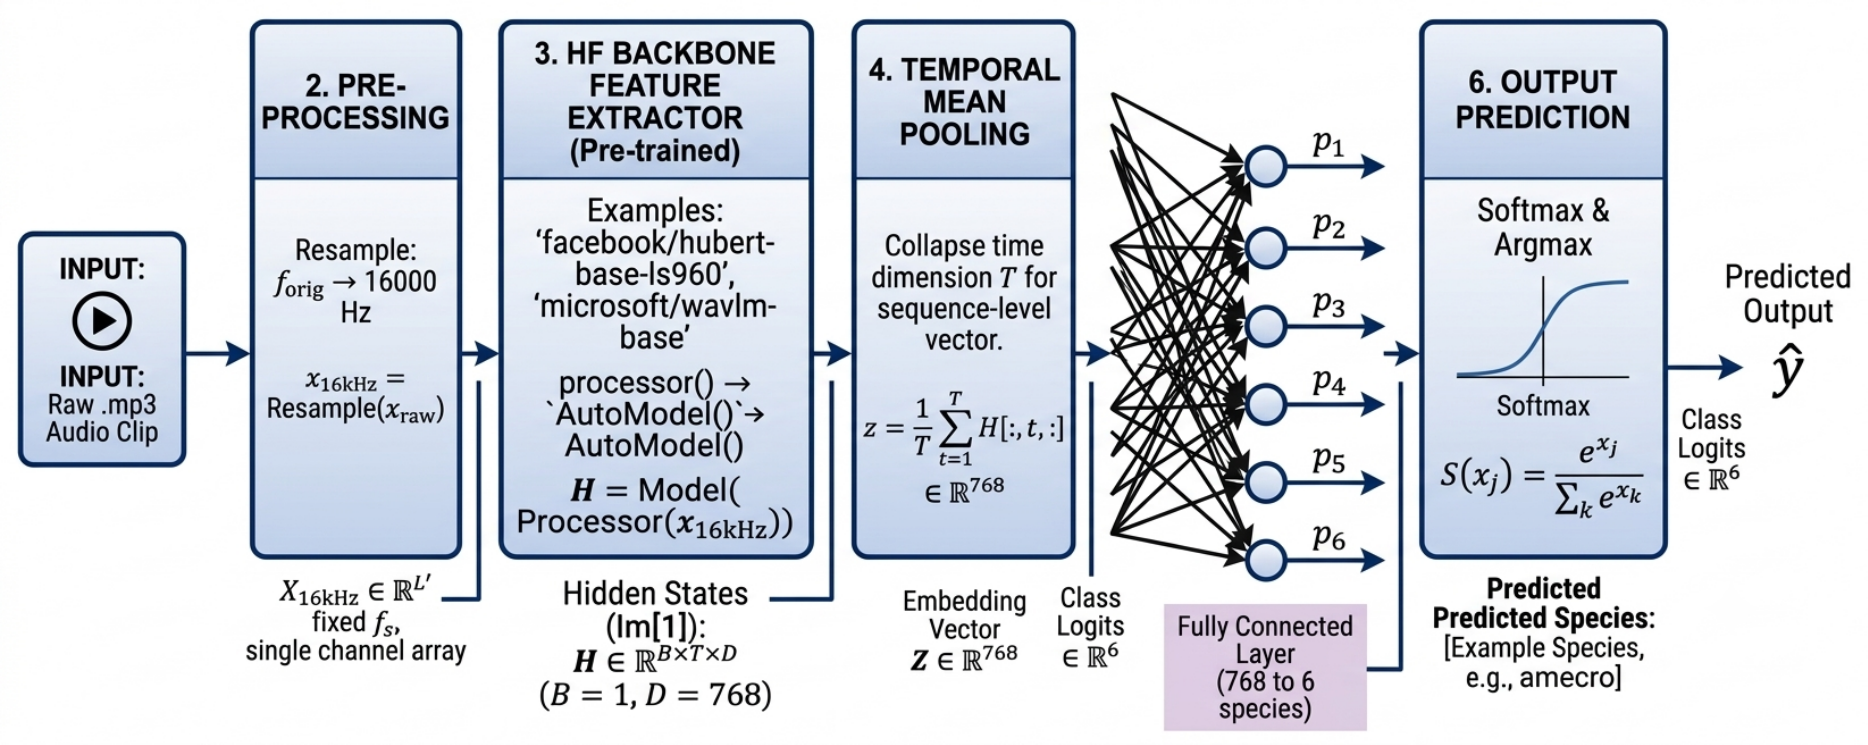

### LGC - scores for K shot

In [1]:
import os
import json
import torch
import torch.nn as nn
from torch.func import vmap, functional_call, jacrev
import numpy as np

In [2]:

# Set fixed seed for reproducibility across all feature runs
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def get_first_k_subset(features: np.ndarray, labels: np.ndarray, shots_per_class: int):
    """
    Deterministically selects the first `shots_per_class` samples for each class
    in the order they appear in the archive.
    """
    selected_indices = []
    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        if len(c_indices) < shots_per_class:
            raise ValueError(f"Class {c} only has {len(c_indices)} samples; cannot pick {shots_per_class}.")
        selected_indices.extend(c_indices[:shots_per_class])

    selected_indices = np.array(selected_indices)
    return features[selected_indices], labels[selected_indices]

def compute_linear_lgc(features: np.ndarray, labels: np.ndarray, num_classes: int = 6):
    N, D = features.shape
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 1. Normalize features (L2 sphere)
    norms = np.linalg.norm(features, axis=1, keepdims=True) + 1e-8
    features_norm = torch.tensor(features / norms, dtype=torch.float32, device=device)

    # 2. Instantiate Linear Model with fixed seed
    torch.manual_seed(SEED)
    model = LinearProbe(input_dim=D, num_classes=num_classes).to(device)
    model.eval()

    params = dict(model.named_parameters())
    buffers = dict(model.named_buffers())

    # Single-sample logit function: (D,) -> (C,)
    def predict_single(p, b, x_vec):
        return functional_call(model, (p, b), x_vec.unsqueeze(0)).squeeze(0)

    # Vectorized per-sample Jacobian w.r.t model parameters
    # jacrev produces dict of tensors with shape (N, C, *param_shape)
    sample_jac_fn = vmap(jacrev(predict_single, argnums=0), in_dims=(None, None, 0))
    jac_dict = sample_jac_fn(params, buffers, features_norm)

    # Flatten and concatenate parameters into (N, C * P)
    flat_jacs = [g.reshape(N, -1) for g in jac_dict.values()]
    J = torch.cat(flat_jacs, dim=1)  # Shape: (N, Total_Grad_Dim)

    # Compute empirical NTK: Theta = J @ J.T (N x N)
    Theta = (J @ J.T).detach().cpu().numpy()

    # 3. Kernel Centering
    H = np.eye(N) - (1.0 / N) * np.ones((N, N))
    Theta_tilde = H @ Theta @ H

    # Safely map labels to 0-indexed contiguous array for one-hot encoding
    unique_classes, mapped_labels = np.unique(labels, return_inverse=True)
    Y_onehot = np.eye(num_classes)[mapped_labels]
    K_Y = Y_onehot @ Y_onehot.T
    K_Y_tilde = H @ K_Y @ H

    norm_Theta = np.linalg.norm(Theta_tilde, 'fro') + 1e-12
    norm_KY = np.linalg.norm(K_Y_tilde, 'fro') + 1e-12

    # 4. Class-wise and Overall LGC
    class_scores = {}
    total_alignment = 0.0

    for idx, c in enumerate(unique_classes):
        y_c = (labels == c).astype(np.float64)
        y_c_tilde = y_c - np.mean(y_c)
        
        # Intra-class gradient correlation
        intra_c = float(y_c_tilde.T @ Theta_tilde @ y_c_tilde)
        score_c = intra_c / (norm_Theta * norm_KY)
        
        class_scores[int(c)] = score_c
        total_alignment += score_c

    return float(total_alignment), class_scores

# --- Pipeline Execution ---
SHOTS_LIST = [1, 5, 10, 25]
base_dir = "../model_embeddings" if os.path.exists("../model_embeddings") else "./model_embeddings"[cite: 1]

for K in SHOTS_LIST:
    output_dir = f"../model_scores_{K}_shot/LGC_linear" if os.path.exists("../model_embeddings") else f"./model_scores_{K}_shot/LGC_linear"[cite: 1]
    os.makedirs(output_dir, exist_ok=True)
    
    results = {}
    print(f"\n==================================================")
    print(f"Processing K={K} Shot LGC Scores")
    print(f"==================================================")

    for model_name in sorted(os.listdir(base_dir)):
        model_path = os.path.join(base_dir, model_name)
        if not os.path.isdir(model_path):
            continue
            
        npz_path = os.path.join(model_path, "features.npz")
        if not os.path.exists(npz_path):
            continue
            
        print(f"Calculating Linear LGC for {model_name} ({K}-shot)...")
        data = np.load(npz_path)
        full_features = data["embeddings"]
        full_labels = data["labels"]
        
        # 1. Deterministic subset extraction
        try:
            features, labels = get_first_k_subset(
                full_features, 
                full_labels, 
                shots_per_class=K
            )
        except ValueError as e:
            print(f"  Skipping {model_name}: {e}")
            continue
        
        # 2. Compute LGC
        overall, class_wise = compute_linear_lgc(features, labels, num_classes=6)
        
        results[model_name] = {
            "shots_per_class": K,
            "total_samples": int(features.shape[0]),
            "overall_lgc": overall,
            "class_wise_lgc": class_wise
        }

    # 3. Save JSON for the current K-shot regime
    output_file = os.path.join(output_dir, "all_models_lgc.json")
    with open(output_file, "w") as f:
        json.dump(results, f, indent=4)

    print(f"Saved {K}-shot Linear NTK-LGC scores to {output_file}")


Processing K=1 Shot LGC Scores
Calculating Linear LGC for AVES-bio (1-shot)...
Calculating Linear LGC for BirdAVES-biox-base (1-shot)...
Calculating Linear LGC for DistilHuBERT (1-shot)...
Calculating Linear LGC for HuBERT (1-shot)...
Calculating Linear LGC for Music2Vec (1-shot)...
Calculating Linear LGC for MusicHuBERT (1-shot)...
Calculating Linear LGC for WavLM (1-shot)...
Saved 1-shot Linear NTK-LGC scores to ../model_scores_1_shot/LGC_linear\all_models_lgc.json

Processing K=5 Shot LGC Scores
Calculating Linear LGC for AVES-bio (5-shot)...
Calculating Linear LGC for BirdAVES-biox-base (5-shot)...
Calculating Linear LGC for DistilHuBERT (5-shot)...
Calculating Linear LGC for HuBERT (5-shot)...
Calculating Linear LGC for Music2Vec (5-shot)...
Calculating Linear LGC for MusicHuBERT (5-shot)...
Calculating Linear LGC for WavLM (5-shot)...
Saved 5-shot Linear NTK-LGC scores to ../model_scores_5_shot/LGC_linear\all_models_lgc.json

Processing K=10 Shot LGC Scores
Calculating Linear LG

# Training the neural neetwork

## We have used two cross-validation-based approaches
#### 1. Regularized training with cross validation
#### 2. Optimal epoch training with cross validation

##### Cross validation split: training: 80\% and Validation split: 20\%.

### 1. Training the classifier with optimal lamnbda using Cross Validation

A grid search for the optimal regularization parameter lambda is performed over the range of values: [1e-3, 1e-2, 0.1, 1, 10].

The lambda $\lambda$ with least average cross entropy loss over all splits is chosen. The model is trained on all N samples with this optimal lambda $\lambda^*$
$$\lambda^* = \arg\min_{\lambda} \left( \frac{1}{V} \sum_{v=1}^V \mathcal{L}_{\text{val}}^{(v)}(\lambda) \right)$$


1. Loss function: Cross entropy loss (Regularization is implicit - optimizer)
2. Optimizer: Trained using AdamW (torch.optim.AdamW) with a base learning rate $\eta = 0.01$
3. Batch size and epochs: Trained on Full-Batch with 100 epochs fixed. (is sufficient for convergence in few shot case)



##### Only for K = 5, 10, 25

In [4]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

In [8]:

# Deterministic seeding for exact reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def get_first_k_subset(features: np.ndarray, labels: np.ndarray, shots_per_class: int):
    """
    Deterministically selects the first `shots_per_class` samples for each class
    in the order they appear in the archive.
    """
    selected_indices = []
    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        if len(c_indices) < shots_per_class:
            raise ValueError(f"Class {c} has {len(c_indices)} samples; cannot pick {shots_per_class}.")
        selected_indices.extend(c_indices[:shots_per_class])

    selected_indices = np.array(selected_indices)
    return features[selected_indices], labels[selected_indices]

def generate_stratified_folds(labels: np.ndarray, leave_out_per_class: int = 1):
    """
    Partitions the dataset into V stratified folds, holding out `leave_out_per_class`
    samples per class in each validation fold.
    """
    unique_classes = np.unique(labels)
    class_indices = {c: np.where(labels == c)[0] for c in unique_classes}
    shots_per_class = len(class_indices[unique_classes[0]])
    
    num_folds = shots_per_class // leave_out_per_class
    if num_folds < 2:
        raise ValueError(
            f"Cannot perform CV with {shots_per_class} shots and leave_out_per_class={leave_out_per_class}. "
            f"Need at least 2 folds."
        )

    folds = []
    for f in range(num_folds):
        val_idx = []
        train_idx = []
        start = f * leave_out_per_class
        end = start + leave_out_per_class
        
        for c in unique_classes:
            indices = class_indices[c]
            val_idx.extend(indices[start:end])
            train_idx.extend(np.concatenate([indices[:start], indices[end:]]))
            
        folds.append((np.array(train_idx), np.array(val_idx)))

    return folds

def train_linear_probe(
    X_train: torch.Tensor, 
    y_train: torch.Tensor, 
    input_dim: int, 
    num_classes: int, 
    weight_decay: float, 
    epochs: int = 80, 
    lr: float = 0.01,
    seed: int = SEED
):
    """
    Trains a linear probe via full-batch gradient descent with explicit weight decay.
    """
    torch.manual_seed(seed)
    model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(X_train.device)
    model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()

    return model

def evaluate_loss_and_acc(model: nn.Module, X: torch.Tensor, y: torch.Tensor):
    """
    Computes validation cross-entropy loss and accuracy in eval mode.
    """
    model.eval()
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = torch.argmax(logits, dim=1)
        acc = (preds == y).float().mean().item()
    return loss, acc

def tune_lambda_cv(
    features_norm: torch.Tensor,
    labels_tensor: torch.Tensor,
    input_dim: int,
    num_classes: int,
    candidate_lambdas: list,
    leave_out_per_class: int,
    epochs: int = 80,
    lr: float = 0.01
):
    """
    Runs stratified cross-validation strictly within K-shot data across candidate lambdas.
    Returns optimal lambda and the mean CV metrics.
    """
    labels_np = labels_tensor.cpu().numpy()
    folds = generate_stratified_folds(labels_np, leave_out_per_class=leave_out_per_class)
    
    cv_results = {}
    best_lambda = None
    lowest_cv_loss = float("inf")

    for lmbda in candidate_lambdas:
        fold_losses = []
        fold_accs = []
        
        for fold_idx, (train_idx, val_idx) in enumerate(folds):
            X_tr, y_tr = features_norm[train_idx], labels_tensor[train_idx]
            X_va, y_va = features_norm[val_idx], labels_tensor[val_idx]
            
            # Train on training partition of the fold with candidate lambda
            fold_model = train_linear_probe(
                X_train=X_tr,
                y_train=y_tr,
                input_dim=input_dim,
                num_classes=num_classes,
                weight_decay=lmbda,
                epochs=epochs,
                lr=lr,
                seed=SEED + fold_idx
            )
            
            # Evaluate out-of-fold generalization
            val_loss, val_acc = evaluate_loss_and_acc(fold_model, X_va, y_va)
            fold_losses.append(val_loss)
            fold_accs.append(val_acc)

        mean_loss = float(np.mean(fold_losses))
        mean_acc = float(np.mean(fold_accs))
        
        cv_results[str(lmbda)] = {
            "mean_val_loss": mean_loss,
            "mean_val_acc": mean_acc
        }

        # Select lambda minimizing cross-entropy loss (prefer higher lambda on ties)
        if mean_loss <= lowest_cv_loss:
            lowest_cv_loss = mean_loss
            best_lambda = lmbda

    return best_lambda, cv_results

# --- Pipeline Configuration ---
SHOTS_PER_CLASS = 10     # Evaluated on K in {25, 10, 5}
NUM_CLASSES = 6
NUM_EPOCHS = 100
LEARNING_RATE = 0.01

# Tunable samples left out per class for each validation fold
# K=25 -> 5 per class (5-fold) | K=10 -> 2 per class (5-fold) | K=5 -> 1 per class (5-fold)
LEAVE_OUT_MAP = {
    25: 5,
    10: 2,
    5: 1
}
LEAVE_OUT_PER_CLASS = LEAVE_OUT_MAP.get(SHOTS_PER_CLASS, 1)

# CANDIDATE_LAMBDAS = [1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
CANDIDATE_LAMBDAS = [1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Adjust relative paths based on execution from workspace root or inside `models_classification/`[cite: 1]
base_dir = "../model_embeddings" if os.path.exists("../model_embeddings") else "./model_embeddings"[cite: 1]
weights_output_dir = f"../trained_models_{SHOTS_PER_CLASS}_shot/Linear" if os.path.exists("../model_embeddings") else f"./trained_models_{SHOTS_PER_CLASS}_shot/Linear"
os.makedirs(weights_output_dir, exist_ok=True)

training_summary = {}

for model_name in sorted(os.listdir(base_dir)):
    model_path = os.path.join(base_dir, model_name)
    if not os.path.isdir(model_path):
        continue

    npz_path = os.path.join(model_path, "features.npz")
    if not os.path.exists(npz_path):
        continue

    print(f"\n==================================================")
    print(f"Model: {model_name} | {SHOTS_PER_CLASS}-shot | CV Tuning")
    print(f"==================================================")

    data = np.load(npz_path)
    full_features = data["embeddings"]
    full_labels = data["labels"]

    # 1. Deterministic subset extraction (first K samples per class)
    X_train_raw, y_train_raw = get_first_k_subset(
        full_features, 
        full_labels, 
        shots_per_class=SHOTS_PER_CLASS
    )
    
    N, D = X_train_raw.shape

    # 2. Unit-norm feature projection
    norms = np.linalg.norm(X_train_raw, axis=1, keepdims=True) + 1e-8
    features_norm = torch.tensor(X_train_raw / norms, dtype=torch.float32, device=device)
    labels_tensor = torch.tensor(y_train_raw, dtype=torch.long, device=device)

    # 3. In-Sample Stratified Cross-Validation for optimal lambda
    print(f"Running Stratified CV (holding out {LEAVE_OUT_PER_CLASS} sample(s)/class per fold)...")
    best_lambda, cv_grid_results = tune_lambda_cv(
        features_norm=features_norm,
        labels_tensor=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        candidate_lambdas=CANDIDATE_LAMBDAS,
        leave_out_per_class=LEAVE_OUT_PER_CLASS,
        epochs=NUM_EPOCHS,
        lr=LEARNING_RATE
    )
    print(f"Optimal Lambda Selected: {best_lambda} (Validation Loss: {cv_grid_results[str(best_lambda)]['mean_val_loss']:.4f})")

    # 4. Final Retraining on ALL K-shot samples with the optimal lambda
    final_model = train_linear_probe(
        X_train=features_norm,
        y_train=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        weight_decay=best_lambda,
        epochs=NUM_EPOCHS,
        lr=LEARNING_RATE,
        seed=SEED
    )

    final_loss, final_acc = evaluate_loss_and_acc(final_model, features_norm, labels_tensor)
    print(f"Final Retraining on all {N} samples -> Loss: {final_loss:.4f}, Accuracy: {final_acc * 100:.2f}%")

    # 5. Save Model Weights (.pt)
    weights_path = os.path.join(weights_output_dir, f"{model_name}_linear.pt")
    torch.save({
        "model_state_dict": final_model.state_dict(),
        "input_dim": int(D),
        "num_classes": NUM_CLASSES,
        "shots_per_class": SHOTS_PER_CLASS,
        "optimal_lambda": best_lambda,
        "final_train_loss": final_loss,
        "final_train_acc": final_acc,
        "cv_grid_results": cv_grid_results
    }, weights_path)

    training_summary[model_name] = {
        "shots_per_class": SHOTS_PER_CLASS,
        "total_train_samples": int(N),
        "feature_dim": int(D),
        "optimal_lambda": best_lambda,
        "final_train_loss": float(final_loss),
        "final_train_accuracy": float(final_acc),
        "cv_leave_out_per_class": LEAVE_OUT_PER_CLASS,
        "cv_grid_results": cv_grid_results,
        "weights_path": weights_path
    }

# 6. Save Experiment Summary JSON
summary_file = os.path.join(weights_output_dir, "training_summary.json")
with open(summary_file, "w") as f:
    json.dump(training_summary, f, indent=4)

print(f"\nSaved all trained weights and CV summaries to {weights_output_dir}")


Model: AVES-bio | 10-shot | CV Tuning
Running Stratified CV (holding out 2 sample(s)/class per fold)...
Optimal Lambda Selected: 0.0001 (Validation Loss: 1.0113)
Final Retraining on all 60 samples -> Loss: 0.3231, Accuracy: 100.00%

Model: BirdAVES-biox-base | 10-shot | CV Tuning
Running Stratified CV (holding out 2 sample(s)/class per fold)...
Optimal Lambda Selected: 0.0001 (Validation Loss: 0.9440)
Final Retraining on all 60 samples -> Loss: 0.2512, Accuracy: 100.00%

Model: DistilHuBERT | 10-shot | CV Tuning
Running Stratified CV (holding out 2 sample(s)/class per fold)...
Optimal Lambda Selected: 0.0001 (Validation Loss: 1.0489)
Final Retraining on all 60 samples -> Loss: 0.3025, Accuracy: 100.00%

Model: HuBERT | 10-shot | CV Tuning
Running Stratified CV (holding out 2 sample(s)/class per fold)...
Optimal Lambda Selected: 0.0001 (Validation Loss: 1.2378)
Final Retraining on all 60 samples -> Loss: 0.3559, Accuracy: 100.00%

Model: Music2Vec | 10-shot | CV Tuning
Running Stratifi

### Train for  K=1 case

In [9]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

# Deterministic seeding for exact reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def get_first_k_subset(features: np.ndarray, labels: np.ndarray, shots_per_class: int):
    """
    Deterministically selects the first `shots_per_class` samples for each class
    in the order they appear in the archive.
    """
    selected_indices = []
    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        if len(c_indices) < shots_per_class:
            raise ValueError(f"Class {c} has {len(c_indices)} samples; cannot pick {shots_per_class}.")
        selected_indices.extend(c_indices[:shots_per_class])

    selected_indices = np.array(selected_indices)
    return features[selected_indices], labels[selected_indices]

def train_linear_probe(
    X_train: torch.Tensor, 
    y_train: torch.Tensor, 
    input_dim: int, 
    num_classes: int, 
    weight_decay: float, 
    epochs: int = 80, 
    lr: float = 0.01,
    seed: int = SEED
):
    """
    Trains a linear probe via full-batch gradient descent with explicit weight decay.
    """
    torch.manual_seed(seed)
    model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(X_train.device)
    model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()

    return model

def evaluate_loss_and_acc(model: nn.Module, X: torch.Tensor, y: torch.Tensor):
    """
    Computes validation cross-entropy loss and accuracy in eval mode.
    """
    model.eval()
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = torch.argmax(logits, dim=1)
        acc = (preds == y).float().mean().item()
    return loss, acc


# --- Pipeline Configuration ---
SHOTS_PER_CLASS = 1     # 1-shot learning
NUM_CLASSES = 6
NUM_EPOCHS = 100
LEARNING_RATE = 0.01

# Configurable fixed lambda for the 1-shot case
FIXED_LAMBDA = 10.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_dir = "../model_embeddings" if os.path.exists("../model_embeddings") else "./model_embeddings"
weights_output_dir = f"../trained_models_{SHOTS_PER_CLASS}_shot/Linear" if os.path.exists("../model_embeddings") else f"./trained_models_{SHOTS_PER_CLASS}_shot/Linear"
os.makedirs(weights_output_dir, exist_ok=True)

training_summary = {}

for model_name in sorted(os.listdir(base_dir)):
    model_path = os.path.join(base_dir, model_name)
    if not os.path.isdir(model_path):
        continue

    npz_path = os.path.join(model_path, "features.npz")
    if not os.path.exists(npz_path):
        continue

    print(f"\n==================================================")
    print(f"Model: {model_name} | {SHOTS_PER_CLASS}-shot | Fixed Lambda: {FIXED_LAMBDA}")
    print(f"==================================================")

    data = np.load(npz_path)
    full_features = data["embeddings"]
    full_labels = data["labels"]

    # 1. Deterministic subset extraction (first K=1 sample per class)
    X_train_raw, y_train_raw = get_first_k_subset(
        full_features, 
        full_labels, 
        shots_per_class=SHOTS_PER_CLASS
    )
    
    N, D = X_train_raw.shape

    # 2. Unit-norm feature projection
    norms = np.linalg.norm(X_train_raw, axis=1, keepdims=True) + 1e-8
    features_norm = torch.tensor(X_train_raw / norms, dtype=torch.float32, device=device)
    labels_tensor = torch.tensor(y_train_raw, dtype=torch.long, device=device)

    # 3. Direct Retraining on all K-shot samples with the fixed lambda (No CV)
    final_model = train_linear_probe(
        X_train=features_norm,
        y_train=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        weight_decay=FIXED_LAMBDA,
        epochs=NUM_EPOCHS,
        lr=LEARNING_RATE,
        seed=SEED
    )

    final_loss, final_acc = evaluate_loss_and_acc(final_model, features_norm, labels_tensor)
    print(f"Final Training on all {N} samples -> Loss: {final_loss:.4f}, Accuracy: {final_acc * 100:.2f}%")

    # 4. Save Model Weights (.pt)
    weights_path = os.path.join(weights_output_dir, f"{model_name}_linear.pt")
    torch.save({
        "model_state_dict": final_model.state_dict(),
        "input_dim": int(D),
        "num_classes": NUM_CLASSES,
        "shots_per_class": SHOTS_PER_CLASS,
        "optimal_lambda": FIXED_LAMBDA,
        "final_train_loss": final_loss,
        "final_train_acc": final_acc,
        "cv_grid_results": "N/A - 1-shot (Fixed Lambda)"
    }, weights_path)

    training_summary[model_name] = {
        "shots_per_class": SHOTS_PER_CLASS,
        "total_train_samples": int(N),
        "feature_dim": int(D),
        "optimal_lambda": FIXED_LAMBDA,
        "final_train_loss": float(final_loss),
        "final_train_accuracy": float(final_acc),
        "cv_leave_out_per_class": "N/A",
        "cv_grid_results": "N/A - 1-shot (Fixed Lambda)",
        "weights_path": weights_path
    }

# 5. Save Experiment Summary JSON
summary_file = os.path.join(weights_output_dir, "training_summary.json")
with open(summary_file, "w") as f:
    json.dump(training_summary, f, indent=4)

print(f"\nSaved all trained weights and summaries to {weights_output_dir}")


Model: AVES-bio | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.1841, Accuracy: 100.00%

Model: BirdAVES-biox-base | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.1436, Accuracy: 100.00%

Model: DistilHuBERT | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.0553, Accuracy: 100.00%

Model: HuBERT | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.1264, Accuracy: 100.00%

Model: Music2Vec | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.3628, Accuracy: 100.00%

Model: MusicHuBERT | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 0.9650, Accuracy: 100.00%

Model: WavLM | 1-shot | Fixed Lambda: 10.0
Final Training on all 6 samples -> Loss: 1.1008, Accuracy: 100.00%

Saved all trained weights and summaries to ../trained_models_1_shot/Linear


#### Test on unseen data (eval)

In [11]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def evaluate_model(model: nn.Module, X: torch.Tensor, y: torch.Tensor, num_classes: int = 6):
    """
    Computes overall accuracy, test loss, and per-class accuracy on evaluation data.
    """
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = torch.argmax(logits, dim=1)
        
        overall_acc = (preds == y).float().mean().item()
        
        # Per-class accuracy calculation
        class_accs = {}
        for c in range(num_classes):
            mask = (y == c)
            if mask.sum() > 0:
                class_acc = (preds[mask] == y[mask]).float().mean().item()
                class_accs[int(c)] = float(class_acc)
            else:
                class_accs[int(c)] = None

    return overall_acc, loss, class_accs

# --- Configuration & Path Resolution ---
# SHOT_SETTINGS = [5, 10, 25]  # Evaluated shot cases
SHOT_SETTINGS = [1,5,10,25]  # Evaluated shot cases
NUM_CLASSES = 6
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Handle execution from repo root or inside `models_classification/`
base_eval_dir = "../model_embeddings_eval" if os.path.exists("../model_embeddings_eval") else "./model_embeddings_eval"
base_trained_dir_prefix = ".." if os.path.exists("../model_embeddings_eval") else "."
results_output_dir = os.path.join(base_trained_dir_prefix, "model_eval_results")
os.makedirs(results_output_dir, exist_ok=True)

all_shot_rankings = {}

for shots in SHOT_SETTINGS:
    # Check potential subfolder structure for trained models[cite: 2]
    trained_dir = os.path.join(base_trained_dir_prefix, f"trained_models_{shots}_shot", "Linear")
    if not os.path.exists(trained_dir):
        trained_dir = os.path.join(base_trained_dir_prefix, f"trained_models_{shots}_shot")
        
    if not os.path.exists(trained_dir):
        print(f"Directory not found for {shots}-shot models: {trained_dir}, skipping.")
        continue

    print(f"\n=======================================================")
    print(f"         EVALUATING LINEAR PROBES: {shots}-SHOT DATA   ")
    print(f"=======================================================")

    shot_results = {}

    for model_name in sorted(os.listdir(base_eval_dir)):
        eval_model_path = os.path.join(base_eval_dir, model_name)
        if not os.path.isdir(eval_model_path):
            continue

        npz_path = os.path.join(eval_model_path, "features.npz")
        weights_path = os.path.join(trained_dir, f"{model_name}_linear.pt")

        if not os.path.exists(npz_path):
            print(f"Missing features.npz for {model_name} in {eval_model_path}")
            continue
        if not os.path.exists(weights_path):
            print(f"Missing checkpoint {weights_path} for {model_name}")
            continue

        # 1. Load evaluation features & labels
        data = np.load(npz_path)
        eval_features = data["embeddings"]
        eval_labels = data["labels"]

        # 2. Apply unit-norm projection (identical to training pipeline)
        norms = np.linalg.norm(eval_features, axis=1, keepdims=True) + 1e-8
        X_test = torch.tensor(eval_features / norms, dtype=torch.float32, device=device)
        y_test = torch.tensor(eval_labels, dtype=torch.long, device=device)

        # 3. Load model checkpoint
        checkpoint = torch.load(weights_path, map_location=device)
        input_dim = checkpoint["input_dim"]
        
        model = LinearProbe(input_dim=input_dim, num_classes=NUM_CLASSES).to(device)
        model.load_state_dict(checkpoint["model_state_dict"])

        # 4. Compute test metrics
        overall_acc, test_loss, class_accs = evaluate_model(model, X_test, y_test, num_classes=NUM_CLASSES)

        shot_results[model_name] = {
            "overall_accuracy": float(overall_acc),
            "test_loss": float(test_loss),
            "optimal_lambda": checkpoint.get("optimal_lambda", None),
            "total_eval_samples": int(X_test.shape[0]),
            "class_wise_accuracy": class_accs
        }

    # 5. Rank models by overall test accuracy (descending)
    ranked_models = sorted(
        shot_results.items(), 
        key=lambda item: item[1]["overall_accuracy"], 
        reverse=True
    )

    print(f"\n--- {shots}-Shot Ranking Summary ---")
    print(f"{'Rank':<5} | {'Model Name':<22} | {'Accuracy':<10} | {'Test Loss':<10} | {'Tuned λ':<8}")
    print("-" * 65)
    
    ranked_dict = {}
    for rank, (name, metrics) in enumerate(ranked_models, start=1):
        tuned_lambda = metrics['optimal_lambda']
        lambda_str = f"{tuned_lambda:.4f}" if isinstance(tuned_lambda, float) else str(tuned_lambda)
        print(f"{rank:<5} | {name:<22} | {metrics['overall_accuracy']*100:>6.2f}%    | {metrics['test_loss']:>8.4f}  | {lambda_str:<8}")
        
        ranked_dict[name] = {
            "rank": rank,
            **metrics
        }

    all_shot_rankings[f"{shots}_shot"] = ranked_dict

    # Save shot-specific evaluation output
    shot_output_file = os.path.join(results_output_dir, f"linear_eval_{shots}_shot.json")
    with open(shot_output_file, "w") as f:
        json.dump(ranked_dict, f, indent=4)

# 6. Save consolidated evaluation JSON across all shot cases
consolidated_file = os.path.join(results_output_dir, "all_linear_eval_rankings.json")
with open(consolidated_file, "w") as f:
    json.dump(all_shot_rankings, f, indent=4)

print(f"\nAll evaluations complete. Consolidated rankings saved to: {consolidated_file}")


         EVALUATING LINEAR PROBES: 1-SHOT DATA   

--- 1-Shot Ranking Summary ---
Rank  | Model Name             | Accuracy   | Test Loss  | Tuned λ 
-----------------------------------------------------------------
1     | BirdAVES-biox-base     |  40.00%    |   1.7191  | 10.0000 
2     | DistilHuBERT           |  36.00%    |   1.6741  | 10.0000 
3     | AVES-bio               |  35.33%    |   1.7031  | 10.0000 
4     | HuBERT                 |  34.67%    |   1.6978  | 10.0000 
5     | Music2Vec              |  30.00%    |   1.7646  | 10.0000 
6     | WavLM                  |  28.67%    |   1.7065  | 10.0000 
7     | MusicHuBERT            |  24.00%    |   1.7660  | 10.0000 

         EVALUATING LINEAR PROBES: 5-SHOT DATA   

--- 5-Shot Ranking Summary ---
Rank  | Model Name             | Accuracy   | Test Loss  | Tuned λ 
-----------------------------------------------------------------
1     | AVES-bio               |  63.33%    |   1.2199  | 1.0000  
2     | BirdAVES-biox-base    

### 2. Train using fixed epochs (No L2 regularization)

A search is performed for the optimal epoch in the range of [1,200]

1. {Loss function:} Cross entropy loss
1. {Optimizer:} Trained using AdamW (torch.optim.AdamW) with a base learning rate $\eta = 0.01$ and weight\_decay $= 0.0$
1. {Batch size and epochs:} Trained on Full-Batch with the chosen number of epochs.

This approach cannot be followed for 1 shot case as there is only one sample per class. For this, we have chosen the optimal stopping point as the elbow point of the training loss versus no of epochs curve.

In [16]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

# Deterministic seeding for exact reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def get_first_k_subset(features: np.ndarray, labels: np.ndarray, shots_per_class: int):
    """
    Deterministically selects the first `shots_per_class` samples for each class
    in the order they appear in the archive.
    """
    selected_indices = []
    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        if len(c_indices) < shots_per_class:
            raise ValueError(f"Class {c} has {len(c_indices)} samples; cannot pick {shots_per_class}.")
        selected_indices.extend(c_indices[:shots_per_class])

    selected_indices = np.array(selected_indices)
    return features[selected_indices], labels[selected_indices]

def generate_stratified_folds(labels: np.ndarray, leave_out_per_class: int = 1):
    """
    Partitions the dataset into V stratified folds, holding out `leave_out_per_class`
    samples per class in each validation fold.
    """
    unique_classes = np.unique(labels)
    class_indices = {c: np.where(labels == c)[0] for c in unique_classes}
    shots_per_class = len(class_indices[unique_classes[0]])
    
    num_folds = shots_per_class // leave_out_per_class
    if num_folds < 2:
        raise ValueError(f"Need at least 2 folds for CV. Received shots={shots_per_class}, leave_out={leave_out_per_class}.")

    folds = []
    for f in range(num_folds):
        val_idx = []
        train_idx = []
        start = f * leave_out_per_class
        end = start + leave_out_per_class
        
        for c in unique_classes:
            indices = class_indices[c]
            val_idx.extend(indices[start:end])
            train_idx.extend(np.concatenate([indices[:start], indices[end:]]))
            
        folds.append((np.array(train_idx), np.array(val_idx)))

    return folds

def tune_epochs_cv(
    features_norm: torch.Tensor,
    labels_tensor: torch.Tensor,
    input_dim: int,
    num_classes: int,
    max_epochs: int,
    leave_out_per_class: int,
    lr: float = 0.01
):
    """
    Finds the optimal epoch count using stratified CV with zero explicit regularisation.
    """
    labels_np = labels_tensor.cpu().numpy()
    folds = generate_stratified_folds(labels_np, leave_out_per_class=leave_out_per_class)
    num_folds = len(folds)
    
    # Store validation loss for each epoch across folds: shape (num_folds, max_epochs)
    val_loss_curve = np.zeros((num_folds, max_epochs))
    val_acc_curve = np.zeros((num_folds, max_epochs))
    criterion = nn.CrossEntropyLoss()

    for fold_idx, (train_idx, val_idx) in enumerate(folds):
        X_tr, y_tr = features_norm[train_idx], labels_tensor[train_idx]
        X_va, y_va = features_norm[val_idx], labels_tensor[val_idx]

        torch.manual_seed(SEED + fold_idx)
        model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(features_norm.device)
        
        # Zero weight decay: optimization relies entirely on epoch early stopping
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

        for epoch in range(max_epochs):
            model.train()
            optimizer.zero_grad()
            logits = model(X_tr)
            loss = criterion(logits, y_tr)
            loss.backward()
            optimizer.step()

            # Record out-of-fold metrics
            model.eval()
            with torch.no_grad():
                val_logits = model(X_va)
                v_loss = criterion(val_logits, y_va).item()
                v_acc = (torch.argmax(val_logits, dim=1) == y_va).float().mean().item()
                
            val_loss_curve[fold_idx, epoch] = v_loss
            val_acc_curve[fold_idx, epoch] = v_acc

    # Average loss across all folds for each epoch (1-indexed)
    mean_val_loss = np.mean(val_loss_curve, axis=0)
    mean_val_acc = np.mean(val_acc_curve, axis=0)

    # Optimal epoch minimizes mean validation cross-entropy loss
    optimal_epoch = int(np.argmin(mean_val_loss)) + 1
    best_loss = float(mean_val_loss[optimal_epoch - 1])
    best_acc = float(mean_val_acc[optimal_epoch - 1])

    return optimal_epoch, best_loss, best_acc

def train_linear_probe(
    X_train: torch.Tensor, 
    y_train: torch.Tensor, 
    input_dim: int, 
    num_classes: int, 
    epochs: int, 
    lr: float = 0.01
):
    """
    Retrains the linear probe on full K-shot data for exactly `epochs` iterations.
    """
    torch.manual_seed(SEED)
    model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(X_train.device)
    model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        final_logits = model(X_train)
        final_loss = criterion(final_logits, y_train).item()
        preds = torch.argmax(final_logits, dim=1)
        final_acc = (preds == y_train).float().mean().item()

    return model, final_loss, final_acc

# --- Pipeline Configuration ---
SHOTS_PER_CLASS = 5     # Set to 25, 10, or 5
NUM_CLASSES = 6
MAX_EPOCHS = 400
LEARNING_RATE = 0.01

LEAVE_OUT_MAP = {
    25: 5,
    10: 2,
    5: 1
}
LEAVE_OUT_PER_CLASS = LEAVE_OUT_MAP.get(SHOTS_PER_CLASS, 1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_dir = "../model_embeddings" if os.path.exists("../model_embeddings") else "./model_embeddings"
weights_output_dir = (
    f"../trained_models_epoch_tuned_{SHOTS_PER_CLASS}_shot/Linear" 
    if os.path.exists("../model_embeddings") 
    else f"./trained_models_epoch_tuned_{SHOTS_PER_CLASS}_shot/Linear"
)
os.makedirs(weights_output_dir, exist_ok=True)

training_summary = {}

for model_name in sorted(os.listdir(base_dir)):
    model_path = os.path.join(base_dir, model_name)
    if not os.path.isdir(model_path):
        continue

    npz_path = os.path.join(model_path, "features.npz")
    if not os.path.exists(npz_path):
        continue

    print(f"\n==================================================")
    print(f"Model: {model_name} | {SHOTS_PER_CLASS}-shot | Epoch CV Tuning")
    print(f"==================================================")

    data = np.load(npz_path)
    full_features = data["embeddings"]
    full_labels = data["labels"]

    # 1. Deterministic subset extraction
    X_train_raw, y_train_raw = get_first_k_subset(
        full_features, 
        full_labels, 
        shots_per_class=SHOTS_PER_CLASS
    )
    N, D = X_train_raw.shape

    # 2. Unit-norm feature projection
    norms = np.linalg.norm(X_train_raw, axis=1, keepdims=True) + 1e-8
    features_norm = torch.tensor(X_train_raw / norms, dtype=torch.float32, device=device)
    labels_tensor = torch.tensor(y_train_raw, dtype=torch.long, device=device)

    # 3. Stratified CV across epochs (0 to MAX_EPOCHS)
    print(f"Searching for optimal epoch in range [1, {MAX_EPOCHS}] (holding out {LEAVE_OUT_PER_CLASS}/class)...")
    optimal_epoch, best_val_loss, best_val_acc = tune_epochs_cv(
        features_norm=features_norm,
        labels_tensor=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        max_epochs=MAX_EPOCHS,
        leave_out_per_class=LEAVE_OUT_PER_CLASS,
        lr=LEARNING_RATE
    )
    print(f"Optimal Epoch Found: {optimal_epoch} (CV Validation Loss: {best_val_loss:.4f}, Accuracy: {best_val_acc*100:.2f}%)")

    # 4. Final Retraining on all K-shot samples for optimal_epoch
    final_model, train_loss, train_acc = train_linear_probe(
        X_train=features_norm,
        y_train=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        epochs=optimal_epoch,
        lr=LEARNING_RATE
    )
    print(f"Retrained on full {N} samples -> Final Train Loss: {train_loss:.4f}, Accuracy: {train_acc*100:.2f}%")

    # 5. Save Model Checkpoint
    weights_path = os.path.join(weights_output_dir, f"{model_name}_linear.pt")
    torch.save({
        "model_state_dict": final_model.state_dict(),
        "input_dim": int(D),
        "num_classes": NUM_CLASSES,
        "shots_per_class": SHOTS_PER_CLASS,
        "optimal_epoch": optimal_epoch,
        "weight_decay": 0.0,
        "final_train_loss": train_loss,
        "final_train_acc": train_acc
    }, weights_path)

    training_summary[model_name] = {
        "shots_per_class": SHOTS_PER_CLASS,
        "total_train_samples": int(N),
        "feature_dim": int(D),
        "optimal_epoch": optimal_epoch,
        "cv_val_loss": best_val_loss,
        "cv_val_acc": best_val_acc,
        "final_train_loss": float(train_loss),
        "final_train_accuracy": float(train_acc),
        "weights_path": weights_path
    }

# 6. Save Run Summary JSON
summary_file = os.path.join(weights_output_dir, "training_summary.json")
with open(summary_file, "w") as f:
    json.dump(training_summary, f, indent=4)

print(f"\nAll models trained and checkpoints saved to {weights_output_dir}")


Model: AVES-bio | 5-shot | Epoch CV Tuning
Searching for optimal epoch in range [1, 400] (holding out 1/class)...
Optimal Epoch Found: 62 (CV Validation Loss: 1.5136, Accuracy: 56.67%)
Retrained on full 30 samples -> Final Train Loss: 0.4565, Accuracy: 100.00%

Model: BirdAVES-biox-base | 5-shot | Epoch CV Tuning
Searching for optimal epoch in range [1, 400] (holding out 1/class)...
Optimal Epoch Found: 90 (CV Validation Loss: 1.4219, Accuracy: 53.33%)
Retrained on full 30 samples -> Final Train Loss: 0.2067, Accuracy: 100.00%

Model: DistilHuBERT | 5-shot | Epoch CV Tuning
Searching for optimal epoch in range [1, 400] (holding out 1/class)...
Optimal Epoch Found: 57 (CV Validation Loss: 1.4745, Accuracy: 53.33%)
Retrained on full 30 samples -> Final Train Loss: 0.4429, Accuracy: 100.00%

Model: HuBERT | 5-shot | Epoch CV Tuning
Searching for optimal epoch in range [1, 400] (holding out 1/class)...
Optimal Epoch Found: 31 (CV Validation Loss: 1.7087, Accuracy: 30.00%)
Retrained on ful

### Train for K=1 shot case with no of epochs determined using the elbow of the test loss vs epoch curve

In [17]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

# Deterministic seeding for exact reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def get_first_k_subset(features: np.ndarray, labels: np.ndarray, shots_per_class: int):
    """
    Deterministically selects the first `shots_per_class` samples for each class
    in the order they appear in the archive.
    """
    selected_indices = []
    for c in np.unique(labels):
        c_indices = np.where(labels == c)[0]
        if len(c_indices) < shots_per_class:
            raise ValueError(f"Class {c} has {len(c_indices)} samples; cannot pick {shots_per_class}.")
        selected_indices.extend(c_indices[:shots_per_class])

    selected_indices = np.array(selected_indices)
    return features[selected_indices], labels[selected_indices]

def find_elbow_point(loss_curve: list) -> int:
    """
    Computes the elbow (knee) point of a decreasing convex loss curve using
    the maximum perpendicular distance to the chord connecting the start and end points.
    Returns 1-based optimal epoch index. Compatible with NumPy 2.0+.
    """
    n_points = len(loss_curve)
    if n_points < 3:
        return 1

    epochs = np.arange(1, n_points + 1)
    losses = np.array(loss_curve)

    # Normalize coordinates to [0, 1] for scale-invariant distance calculation
    x_norm = (epochs - epochs[0]) / (epochs[-1] - epochs[0])
    y_norm = (losses - losses[-1]) / (losses[0] - losses[-1] + 1e-12)

    # Vector along the chord from start (x0, y0) to end (x1, y1)
    dx = x_norm[-1] - x_norm[0]
    dy = y_norm[-1] - y_norm[0]
    chord_len = np.sqrt(dx**2 + dy**2) + 1e-12

    # Displacement vectors from start point to all points
    px = x_norm - x_norm[0]
    py = y_norm - y_norm[0]

    # Explicit 2D cross product: |dx * py - dy * px| / chord_len
    perpendicular_distances = np.abs(dx * py - dy * px) / chord_len

    elbow_idx = int(np.argmax(perpendicular_distances))
    return int(epochs[elbow_idx])

def evaluate_loss_curve(
    X_train: torch.Tensor,
    y_train: torch.Tensor,
    input_dim: int,
    num_classes: int,
    max_epochs: int,
    lr: float = 0.01
):
    """
    Simulates training over max_epochs to record the trajectory of training loss
    and determines the optimal elbow epoch.
    """
    torch.manual_seed(SEED)
    model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(X_train.device)
    model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    loss_history = []
    for _ in range(max_epochs):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())

    optimal_epoch = find_elbow_point(loss_history)
    return optimal_epoch, loss_history

def train_linear_probe(
    X_train: torch.Tensor,
    y_train: torch.Tensor,
    input_dim: int,
    num_classes: int,
    epochs: int,
    lr: float = 0.01
):
    """
    Retrains the linear probe on full 1-shot data for exactly `epochs` iterations.
    """
    torch.manual_seed(SEED)
    model = LinearProbe(input_dim=input_dim, num_classes=num_classes).to(X_train.device)
    model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        final_logits = model(X_train)
        final_loss = criterion(final_logits, y_train).item()
        preds = torch.argmax(final_logits, dim=1)
        final_acc = (preds == y_train).float().mean().item()

    return model, final_loss, final_acc

# --- Pipeline Configuration ---
SHOTS_PER_CLASS = 1     # 1-shot regime (N = 6 samples)
NUM_CLASSES = 6
MAX_EPOCHS = 100
LEARNING_RATE = 0.01

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_dir = "../model_embeddings" if os.path.exists("../model_embeddings") else "./model_embeddings"
weights_output_dir = (
    f"../trained_models_epoch_tuned_{SHOTS_PER_CLASS}_shot/Linear"
    if os.path.exists("../model_embeddings")
    else f"./trained_models_epoch_tuned_{SHOTS_PER_CLASS}_shot/Linear"
)
os.makedirs(weights_output_dir, exist_ok=True)

training_summary = {}

for model_name in sorted(os.listdir(base_dir)):
    model_path = os.path.join(base_dir, model_name)
    if not os.path.isdir(model_path):
        continue

    npz_path = os.path.join(model_path, "features.npz")
    if not os.path.exists(npz_path):
        continue

    print(f"\n==================================================")
    print(f"Model: {model_name} | {SHOTS_PER_CLASS}-shot | Train Loss Elbow Tuning")
    print(f"==================================================")

    data = np.load(npz_path)
    full_features = data["embeddings"]
    full_labels = data["labels"]

    # 1. Deterministic subset extraction (first 1 sample per class -> 6 samples)
    X_train_raw, y_train_raw = get_first_k_subset(
        full_features,
        full_labels,
        shots_per_class=SHOTS_PER_CLASS
    )
    N, D = X_train_raw.shape

    # 2. Unit-norm feature projection
    norms = np.linalg.norm(X_train_raw, axis=1, keepdims=True) + 1e-8
    features_norm = torch.tensor(X_train_raw / norms, dtype=torch.float32, device=device)
    labels_tensor = torch.tensor(y_train_raw, dtype=torch.long, device=device)

    # 3. Determine optimal epoch using elbow point on training loss
    print(f"Profiling train loss over {MAX_EPOCHS} epochs to detect elbow point...")
    optimal_epoch, loss_history = evaluate_loss_curve(
        X_train=features_norm,
        y_train=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        max_epochs=MAX_EPOCHS,
        lr=LEARNING_RATE
    )
    print(f"Elbow Epoch Found: {optimal_epoch} (Loss at elbow: {loss_history[optimal_epoch - 1]:.4f})")

    # 4. Final Retraining on the 1-shot data up to optimal_epoch
    final_model, train_loss, train_acc = train_linear_probe(
        X_train=features_norm,
        y_train=labels_tensor,
        input_dim=D,
        num_classes=NUM_CLASSES,
        epochs=optimal_epoch,
        lr=LEARNING_RATE
    )
    print(f"Retrained on {N} samples -> Train Loss: {train_loss:.4f}, Accuracy: {train_acc * 100:.2f}%")

    # 5. Save Model Checkpoint
    weights_path = os.path.join(weights_output_dir, f"{model_name}_linear.pt")
    torch.save({
        "model_state_dict": final_model.state_dict(),
        "input_dim": int(D),
        "num_classes": NUM_CLASSES,
        "shots_per_class": SHOTS_PER_CLASS,
        "optimal_epoch": optimal_epoch,
        "weight_decay": 0.0,
        "final_train_loss": train_loss,
        "final_train_acc": train_acc,
        "loss_history": loss_history
    }, weights_path)

    training_summary[model_name] = {
        "shots_per_class": SHOTS_PER_CLASS,
        "total_train_samples": int(N),
        "feature_dim": int(D),
        "optimal_epoch": optimal_epoch,
        "elbow_train_loss": float(loss_history[optimal_epoch - 1]),
        "final_train_loss": float(train_loss),
        "final_train_accuracy": float(train_acc),
        "weights_path": weights_path
    }

# 6. Save Run Summary JSON
summary_file = os.path.join(weights_output_dir, "training_summary.json")
with open(summary_file, "w") as f:
    json.dump(training_summary, f, indent=4)

print(f"\nAll 1-shot models trained and checkpoints saved to {weights_output_dir}")


Model: AVES-bio | 1-shot | Train Loss Elbow Tuning
Profiling train loss over 100 epochs to detect elbow point...
Elbow Epoch Found: 34 (Loss at elbow: 0.3802)
Retrained on 6 samples -> Train Loss: 0.3629, Accuracy: 100.00%

Model: BirdAVES-biox-base | 1-shot | Train Loss Elbow Tuning
Profiling train loss over 100 epochs to detect elbow point...
Elbow Epoch Found: 33 (Loss at elbow: 0.3413)
Retrained on 6 samples -> Train Loss: 0.3241, Accuracy: 100.00%

Model: DistilHuBERT | 1-shot | Train Loss Elbow Tuning
Profiling train loss over 100 epochs to detect elbow point...
Elbow Epoch Found: 31 (Loss at elbow: 0.3165)
Retrained on 6 samples -> Train Loss: 0.2998, Accuracy: 100.00%

Model: HuBERT | 1-shot | Train Loss Elbow Tuning
Profiling train loss over 100 epochs to detect elbow point...
Elbow Epoch Found: 33 (Loss at elbow: 0.3324)
Retrained on 6 samples -> Train Loss: 0.3158, Accuracy: 100.00%

Model: Music2Vec | 1-shot | Train Loss Elbow Tuning
Profiling train loss over 100 epochs to

### Test on unseen data (eval)

In [19]:
import os
import json
import torch
import torch.nn as nn
import numpy as np

class LinearProbe(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 6):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)

def evaluate_model(model: nn.Module, X: torch.Tensor, y: torch.Tensor, num_classes: int = 6):
    """
    Computes overall accuracy, test loss, and per-class accuracy on evaluation data.
    """
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = torch.argmax(logits, dim=1)
        
        overall_acc = (preds == y).float().mean().item()
        
        # Per-class accuracy calculation
        class_accs = {}
        for c in range(num_classes):
            mask = (y == c)
            if mask.sum() > 0:
                class_acc = (preds[mask] == y[mask]).float().mean().item()
                class_accs[int(c)] = float(class_acc)
            else:
                class_accs[int(c)] = None

    return overall_acc, loss, class_accs

# --- Configuration & Path Resolution ---
# SHOT_SETTINGS = [5, 10, 25]  # Evaluated shot cases
SHOT_SETTINGS = [1,5,10,25]  # Evaluated shot cases

NUM_CLASSES = 6
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Handle directory resolution across workspace root and subdirectories[cite: 2]
base_eval_dir = "../model_embeddings_eval" if os.path.exists("../model_embeddings_eval") else "./model_embeddings_eval"
base_trained_dir_prefix = ".." if os.path.exists("../model_embeddings_eval") else "."

results_output_dir = os.path.join(base_trained_dir_prefix, "model_eval_results_epoch_tuned")
os.makedirs(results_output_dir, exist_ok=True)

all_shot_rankings = {}

for shots in SHOT_SETTINGS:
    trained_dir = os.path.join(
        base_trained_dir_prefix, 
        f"trained_models_epoch_tuned_{shots}_shot", 
        "Linear"
    )
    
    if not os.path.exists(trained_dir):
        # Fallback to direct shot folder if no 'Linear' subfolder exists
        trained_dir = os.path.join(
            base_trained_dir_prefix, 
            f"trained_models_epoch_tuned_{shots}_shot"
        )
        
    if not os.path.exists(trained_dir):
        print(f"Directory not found for {shots}-shot models: {trained_dir}, skipping.")
        continue

    print(f"\n=======================================================")
    print(f"   EVALUATING EPOCH-TUNED LINEAR PROBES: {shots}-SHOT DATA   ")
    print(f"=======================================================")

    shot_results = {}

    for model_name in sorted(os.listdir(base_eval_dir)):
        eval_model_path = os.path.join(base_eval_dir, model_name)
        if not os.path.isdir(eval_model_path):
            continue

        npz_path = os.path.join(eval_model_path, "features.npz")
        weights_path = os.path.join(trained_dir, f"{model_name}_linear.pt")

        if not os.path.exists(npz_path):
            print(f"Missing features.npz for {model_name} in {eval_model_path}")
            continue
        if not os.path.exists(weights_path):
            print(f"Missing checkpoint {weights_path} for {model_name}")
            continue

        # 1. Load evaluation features & labels
        data = np.load(npz_path)
        eval_features = data["embeddings"]
        eval_labels = data["labels"]

        # 2. Apply unit-norm projection identical to training
        norms = np.linalg.norm(eval_features, axis=1, keepdims=True) + 1e-8
        X_test = torch.tensor(eval_features / norms, dtype=torch.float32, device=device)
        y_test = torch.tensor(eval_labels, dtype=torch.long, device=device)

        # 3. Load model checkpoint
        checkpoint = torch.load(weights_path, map_location=device)
        input_dim = checkpoint["input_dim"]
        
        model = LinearProbe(input_dim=input_dim, num_classes=NUM_CLASSES).to(device)
        model.load_state_dict(checkpoint["model_state_dict"])

        # 4. Evaluate metrics
        overall_acc, test_loss, class_accs = evaluate_model(
            model, 
            X_test, 
            y_test, 
            num_classes=NUM_CLASSES
        )

        shot_results[model_name] = {
            "overall_accuracy": float(overall_acc),
            "test_loss": float(test_loss),
            "optimal_epoch": checkpoint.get("optimal_epoch", None),
            "total_eval_samples": int(X_test.shape[0]),
            "class_wise_accuracy": class_accs
        }

    # 5. Rank models by overall test accuracy (descending)
    ranked_models = sorted(
        shot_results.items(), 
        key=lambda item: item[1]["overall_accuracy"], 
        reverse=True
    )

    print(f"\n--- {shots}-Shot Ranking Summary (Early-Stopped / Epoch-Tuned) ---")
    print(f"{'Rank':<5} | {'Model Name':<22} | {'Accuracy':<10} | {'Test Loss':<10} | {'Epochs':<8}")
    print("-" * 65)
    
    ranked_dict = {}
    for rank, (name, metrics) in enumerate(ranked_models, start=1):
        opt_epoch = metrics["optimal_epoch"]
        epoch_str = str(opt_epoch) if opt_epoch is not None else "N/A"
        print(f"{rank:<5} | {name:<22} | {metrics['overall_accuracy']*100:>6.2f}%    | {metrics['test_loss']:>8.4f}  | {epoch_str:<8}")
        
        ranked_dict[name] = {
            "rank": rank,
            **metrics
        }

    all_shot_rankings[f"{shots}_shot"] = ranked_dict

    # Save shot-specific evaluation JSON
    shot_output_file = os.path.join(results_output_dir, f"linear_eval_{shots}_shot.json")
    with open(shot_output_file, "w") as f:
        json.dump(ranked_dict, f, indent=4)

# 6. Save consolidated evaluation JSON across all shot cases
consolidated_file = os.path.join(results_output_dir, "all_linear_eval_rankings.json")
with open(consolidated_file, "w") as f:
    json.dump(all_shot_rankings, f, indent=4)

print(f"\nAll evaluations complete. Consolidated rankings saved to: {consolidated_file}")


   EVALUATING EPOCH-TUNED LINEAR PROBES: 1-SHOT DATA   

--- 1-Shot Ranking Summary (Early-Stopped / Epoch-Tuned) ---
Rank  | Model Name             | Accuracy   | Test Loss  | Epochs  
-----------------------------------------------------------------
1     | BirdAVES-biox-base     |  40.00%    |   1.6155  | 33      
2     | AVES-bio               |  35.33%    |   1.5857  | 34      
3     | DistilHuBERT           |  34.00%    |   1.6314  | 31      
4     | HuBERT                 |  34.00%    |   1.6566  | 33      
5     | Music2Vec              |  32.00%    |   1.7378  | 41      
6     | WavLM                  |  27.33%    |   1.7786  | 32      
7     | MusicHuBERT            |  23.33%    |   1.8118  | 28      

   EVALUATING EPOCH-TUNED LINEAR PROBES: 5-SHOT DATA   

--- 5-Shot Ranking Summary (Early-Stopped / Epoch-Tuned) ---
Rank  | Model Name             | Accuracy   | Test Loss  | Epochs  
-----------------------------------------------------------------
1     | AVES-bio         